In [1]:
%pip install matplotlib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
%pip install seaborn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [7]:
import pandas as pd
import os

# Define the dataset path using your absolute file path
dataset_path = r"C:\Users\personal laptop\Lab8_DataVisualization_Olorvida\spotify_top_1000_tracks.csv"

# Load dataset
df = pd.read_csv(dataset_path, encoding="utf-8")

# Convert release_date and extract year
df['release_date'] = pd.to_datetime(df['release_date'], errors='coerce')
df['year'] = df['release_date'].dt.year

# FIX: We REMOVE the line that tried to create 'duration_min'
# because it already exists in the CSV file you loaded.
# (The 'duration_min' column is ready for use!)

print(" Dataset loaded and basic preprocessing complete!")
print(df.head(3))


 Dataset loaded and basic preprocessing complete!
                 track_name          artist  \
0  All The Stars (with SZA)  Kendrick Lamar   
1                   Starboy      The Weeknd   
2                  Señorita    Shawn Mendes   

                                               album release_date  popularity  \
0  Black Panther The Album Music From And Inspire...   2018-02-09          95   
1                                            Starboy   2016-11-25          90   
2                                           Señorita   2019-06-21          80   

                                         spotify_url                      id  \
0  https://open.spotify.com/track/3GCdLUSnKSMJhs4...  3GCdLUSnKSMJhs4Tj6CV3s   
1  https://open.spotify.com/track/7MXVkk9YMctZqd1...  7MXVkk9YMctZqd1Srtv4MB   
2  https://open.spotify.com/track/0TK2YIli7K1leLo...  0TK2YIli7K1leLovkQiNik   

   duration_min    year  
0      3.869767  2018.0  
1      3.840883  2016.0  
2      3.182667  2019.0  


In [8]:
import numpy as np

# Clean up text columns
df['track_name'] = df['track_name'].str.strip()
df['artist'] = df['artist'].str.strip()
df['album'] = df['album'].str.strip()

# Convert 'year' to integer
df['year'] = df['year'].fillna(0).astype(int)

# Drop unnecessary columns
cols_to_drop = ['spotify_url', 'id', 'release_date']

# Check for and add other common audio feature columns if they exist
if 'time_signature' in df.columns:
 cols_to_drop.append('time_signature')
if 'key' in df.columns:
 cols_to_drop.append('key')
if 'mode' in df.columns:
 cols_to_drop.append('mode')
df = df.drop(columns=cols_to_drop, errors='ignore')

# Feature Engineering: Tempo Category
tempo_bins = [0, 100, 140, np.inf]
tempo_labels = ['Slow', 'Medium', 'Fast']
if 'tempo' in df.columns:
 df['tempo_category'] = pd.cut( # Create tempo category column
 df['tempo'], bins=tempo_bins,
 labels=tempo_labels, right=False
 )
 print("Feature 'tempo_category' created.")
else:
 print("Warning: 'tempo' column not found; skipping 'tempo_category' creation.")

# Remove duplicates
df = df.drop_duplicates(subset=['track_name', 'artist'], keep='first')
print(f" Data cleaning and feature engineering complete.")
print(f"Final Row Count after deduplication: {len(df)}")

 Data cleaning and feature engineering complete.
Final Row Count after deduplication: 971


In [20]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

student_name = "Olorvida"
student_id = "TUPM-26-1850" # Replace with your actual ID
id_num = int(student_id[-3:])
color1 = f"#{(id_num * 7) % 256:02x}{(id_num * 3) % 256:02x}{(id_num * 5)
% 256:02x}"
color2 = f"#{(id_num * 2) % 256:02x}{(id_num * 9) % 256:02x}{(id_num * 4)
% 256:02x}"

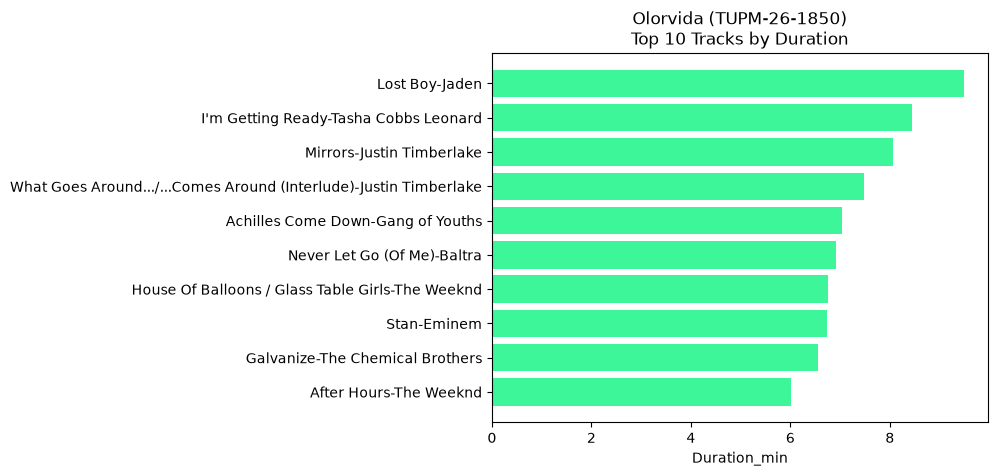

In [33]:
longest = df.nlargest(10, 'duration_min')
longest['label'] = (longest['track_name'] + "-" + longest['artist'])
plt.barh(longest['label'], longest['duration_min'], color=color1)
plt.xlabel('Duration_min')
plt.title(f"{student_name} ({student_id})\nTop 10 Tracks by Duration")
plt.gca().invert_yaxis()
plt.show()

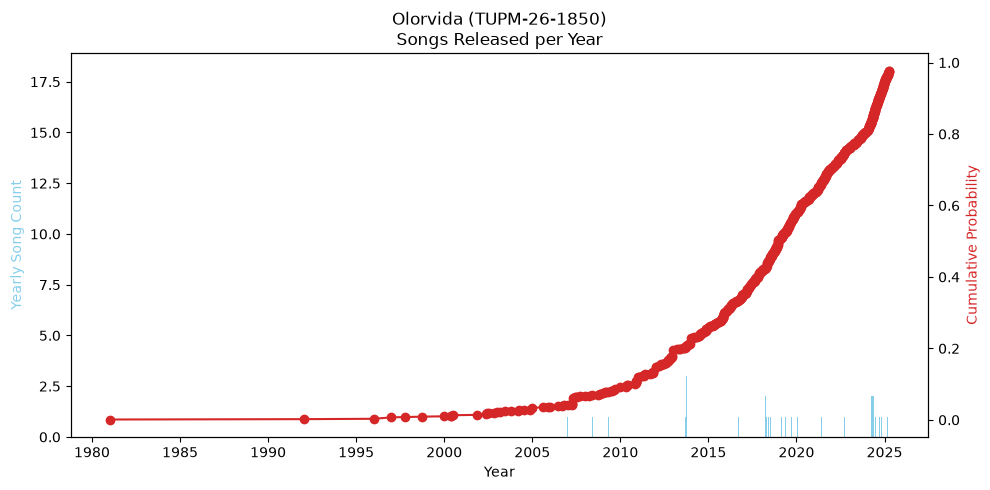

In [54]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("spotify_top_1000_tracks.csv")

# Convert release_date and extract year
df['release_date'] = pd.to_datetime(df['release_date'], errors='coerce')
df['year'] = df['release_date'].dt.year

release_date = df.groupby("release_date").size().sort_index()

# Convert cumulative counts to cumulative probability (0.0 to 1.0)
cumulative_prob = release_date.cumsum() / len(df)

color_bar = "skyblue"
color_line = "tab:red"

fig, ax1 = plt.subplots(figsize=(10, 5))

# Bar chart for yearly counts
ax1.bar(release_date.index, release_date.values, color=color_bar, label="Yearly Count")
ax1.set_xlabel("Year")
ax1.set_ylabel("Yearly Song Count", color=color_bar)

# Line chart for cumulative probability
ax2 = ax1.twinx()
ax2.plot(cumulative_prob.index, cumulative_prob.values, color=color_line, marker="o", label="Cumulative Probability")
ax2.set_ylabel("Cumulative Probability", color=color_line)

plt.title(f"{student_name} ({student_id})\nSongs Released per Year")
plt.tight_layout()
plt.show()


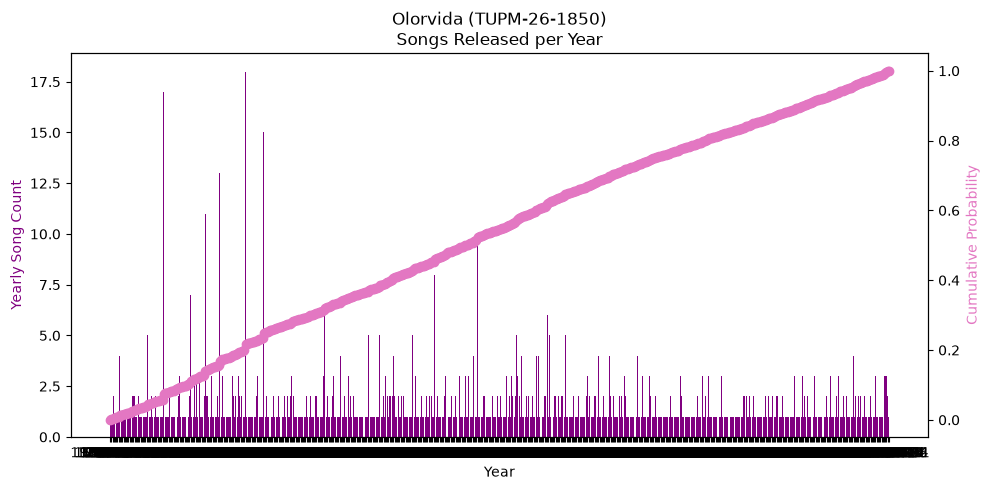

In [57]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("spotify_top_1000_tracks.csv")
release_date = df.groupby("release_date").size().sort_index()

# Convert cumulative counts to cumulative probability (0.0 to 1.0)
cumulative_prob = release_date.cumsum() / len(df)

color_bar = "purple"
color_line = "tab:pink"

fig, ax1 = plt.subplots(figsize=(10, 5))

# Bar chart for yearly counts
ax1.bar(release_date.index, release_date.values, color=color_bar, label="Yearly Count")
ax1.set_xlabel("Year")
ax1.set_ylabel("Yearly Song Count", color=color_bar)

# Line chart for cumulative probability
ax2 = ax1.twinx()
ax2.plot(cumulative_prob.index, cumulative_prob.values, color=color_line, marker="o", label="Cumulative Probability")
ax2.set_ylabel("Cumulative Probability", color=color_line)

plt.title(f"{student_name} ({student_id})\nSongs Released per Year")
plt.tight_layout()
plt.show()


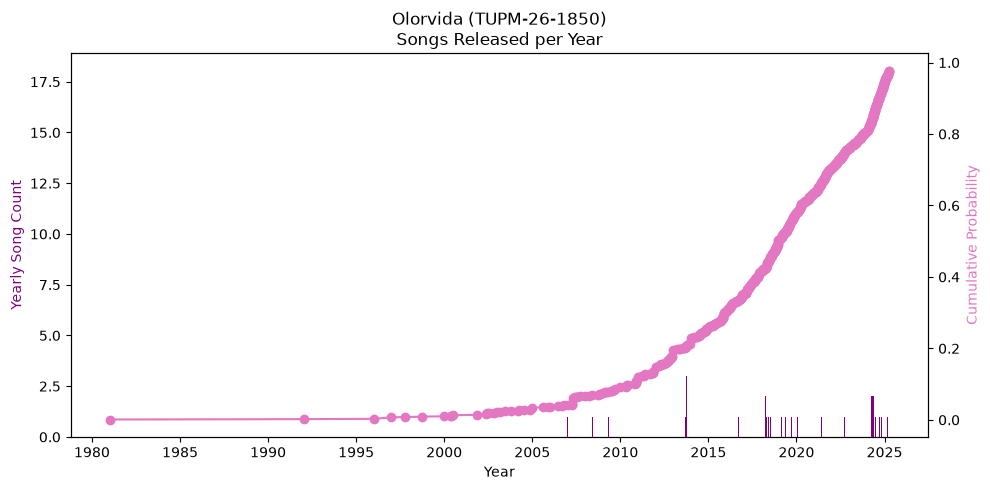

In [56]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("spotify_top_1000_tracks.csv")

# Convert release_date and extract year
df['release_date'] = pd.to_datetime(df['release_date'], errors='coerce')
df['year'] = df['release_date'].dt.year

release_date = df.groupby("release_date").size().sort_index()

# Convert cumulative counts to cumulative probability (0.0 to 1.0)
cumulative_prob = release_date.cumsum() / len(df)

color_bar = "purple"
color_line = "tab:pink"

fig, ax1 = plt.subplots(figsize=(10, 5))

# Bar chart for yearly counts
ax1.bar(release_date.index, release_date.values, color=color_bar, label="Yearly Count")
ax1.set_xlabel("Year")
ax1.set_ylabel("Yearly Song Count", color=color_bar)

# Line chart for cumulative probability
ax2 = ax1.twinx()
ax2.plot(cumulative_prob.index, cumulative_prob.values, color=color_line, marker="o", label="Cumulative Probability")
ax2.set_ylabel("Cumulative Probability", color=color_line)

plt.title(f"{student_name} ({student_id})\nSongs Released per Year")
plt.tight_layout()
plt.show()


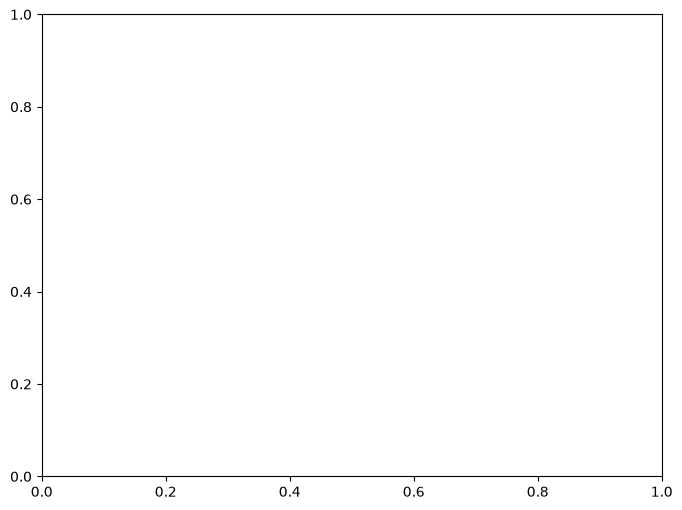

In [61]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation

# 1. Load data and set student-specific parameters
df = pd.read_csv('spotify_top_1000_tracks.csv')
cmap_color = "viridis"

# Convert release_date and extract year
df['release_date'] = pd.to_datetime(df['release_date'], errors='coerce')
df['year'] = df['release_date'].dt.year

years = sorted(df['release_date'].dropna().unique())
fig, ax = plt.subplots(figsize=(8, 6))

# Set consistent axis limits across all frames
xlim = (df['duration_min'].min(), df['duration_min'].max())
ylim = (df['popularity'].min(), df['popularity'].max())

# 2. Define the animation update function
def update(release_date):
    ax.clear()
    subset = df[df['release_date'] <= release_date]  # Cumulative progression over time
    
    ax.hexbin(
        subset['duration_min'], 
        subset['popularity'], 
        gridsize=20, 
        cmap=cmap_color, 
        mincnt=1
    )
    ax.set_xlim(xlim)
    ax.set_ylim(ylim)
    ax.set_xlabel('Duration (min)')
    ax.set_ylabel('Popularity')
    ax.set_title(f"Duration vs Popularity ({int(year)})\n{student_name} - {student_id}")

# 3. Create and display/save the animation
ani = FuncAnimation(fig, update, frames=years, interval=500, repeat=True)
plt.show()
